<a href="https://colab.research.google.com/github/ldiazbusquets/retirement-sim/blob/main/notebook/retirement_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retirement Simulation in Python (Mini Project 2 → Retirement Simulator app)

FIN 414 Applied Project I · Group 6

This notebook runs the **same simulation as our web app** ([live app](https://ldiazbusquets.github.io/retirement-sim/)) in Python, the way we did Mini Project 2 in Colab. It shows that the app keeps the mini project's logic:

1. the same S&P 500 data (^GSPC year-end closes, 1929–2023 → 94 annual returns),
2. the same year-by-year formula: `balance = balance × (1 + return) + contribution`,
3. the same loops: 35 years inside 10,000 simulations,
4. the same outputs: mean, median, probability of reaching the goal, 5th and 95th percentiles, and a histogram.

Because the notebook uses the same seeded random numbers as the app, **Emma's results match the website to the dollar.**

## 1. Data: S&P 500 annual returns

In [1]:
import json, math, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The year-end closes the app uses (pulled from Yahoo Finance ^GSPC, 1929-01-01 to 2024-01-01,
# the same request as Mini Project 2). Read the copy in the repo; in Colab, fetch it from GitHub.
local = Path('../data/sp500_annual_returns.json')
if local.exists():
    data = json.loads(local.read_text())
else:
    url = 'https://raw.githubusercontent.com/ldiazbusquets/retirement-sim/main/data/sp500_annual_returns.json'
    data = json.load(urllib.request.urlopen(url))

closes = pd.DataFrame(data['year_end_close']).set_index('year')['close']
returns = closes.pct_change().dropna()          # annual return = this year's close / last year's close - 1
returns_app = pd.Series([r['return'] for r in data['annual_returns']], index=returns.index)  # the app's copy (6 decimals)

print(f"{len(returns)} annual returns, {returns.index[0]}-{returns.index[-1]}")
print(f"Largest gap between recomputed and app returns: {abs(returns - returns_app).max():.1e}")
print(f"Mean {returns_app.mean():.4%}   Std dev {returns_app.std():.4%}")
print(f"Worst {returns_app.idxmin()} ({returns_app.min():.1%})   Best {returns_app.idxmax()} ({returns_app.max():.1%})")

94 annual returns, 1930-2023
Largest gap between recomputed and app returns: 5.0e-07
Mean 7.7431%   Std dev 18.9133%
Worst 1931 (-47.1%)   Best 1954 (45.0%)


**Optional:** re-download the data exactly as in Mini Project 2 (needs internet and `yfinance`). Uncomment to check that the closes match.

The app's file was saved on Nov 9, 2026; Yahoo can occasionally revise old values slightly.

In [2]:
# !pip install -q yfinance
# import yfinance as yf
# px = yf.download('^GSPC', start='1929-01-01', end='2024-01-01', auto_adjust=False, progress=False)['Close'].squeeze()
# yearly = px.resample('YE').last()
# print(yearly.pct_change().dropna().describe())

## 2. Emma's inputs (the app's defaults)

In [3]:
current_age    = 30
retirement_age = 65
contribution   = 12_000      # dollars per year, added at the END of each year (as in Mini Project 2)
start_balance  = 0
goal           = 1_500_000
n_sims         = 10_000
seed           = 2026

years = retirement_age - current_age
mean, sd = returns_app.mean(), returns_app.std()     # sample standard deviation (n - 1), pandas default
R = returns_app.tolist()
print(f"{years} years of contributions, mean return {mean:.4%}, std dev {sd:.4%}")

35 years of contributions, mean return 7.7431%, std dev 18.9133%


## 3. Seeded random numbers

`np.random` and the browser produce different random numbers, so a NumPy run would give *close* but not identical results. To match the app exactly, this notebook uses the same small generator the app uses (mulberry32) and the same Box-Muller step to turn uniform numbers into normal ones. Same seed → same draws → same results.

In [4]:
def mulberry32(seed):
    a = seed & 0xFFFFFFFF
    def rand():
        nonlocal a
        a = (a + 0x6D2B79F5) & 0xFFFFFFFF
        t = ((a ^ (a >> 15)) * (1 | a)) & 0xFFFFFFFF
        t = ((t + (((t ^ (t >> 7)) * (61 | t)) & 0xFFFFFFFF)) & 0xFFFFFFFF) ^ t
        return ((t ^ (t >> 14)) & 0xFFFFFFFF) / 4294967296
    return rand

def normal_return(rand):
    u1, u2 = 1 - rand(), rand()
    z = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)   # Box-Muller: one standard normal draw
    return max(mean + sd * z, -1.0)                                  # can't lose more than 100%

## 4. The simulation (same loops as Mini Project 2)

In [5]:
def simulate(contribution=contribution, years=years, start_balance=start_balance,
             n_sims=n_sims, seed=seed, timing='end', model='normal'):
    rand = mulberry32(seed)
    outcomes = []
    for s in range(n_sims):                      # outer loop: one simulated life per pass
        balance = start_balance
        for y in range(years):                   # inner loop: one year at a time
            r = normal_return(rand) if model == 'normal' else R[math.floor(rand() * len(R))]
            if timing == 'end':
                balance = balance * (1 + r) + contribution
            else:
                balance = (balance + contribution) * (1 + r)
        outcomes.append(balance)                 # wealth at retirement for this simulation
    return np.array(outcomes)

wealth = simulate()
print(f"{len(wealth):,} simulations finished")

10,000 simulations finished


## 5. Results

In [6]:
def summary(w, goal=goal):
    return pd.Series({
        'Probability of reaching goal': f"{(w >= goal).mean():.1%}",
        'Mean':            f"${w.mean():,.0f}",
        'Median':          f"${np.median(w):,.0f}",
        '5th percentile':  f"${np.percentile(w, 5):,.0f}",
        '25th percentile': f"${np.percentile(w, 25):,.0f}",
        '75th percentile': f"${np.percentile(w, 75):,.0f}",
        '95th percentile': f"${np.percentile(w, 95):,.0f}",
    })

summary(wealth).to_frame("Emma (notebook)")

,Emma (notebook)
Probability of reaching goal,47.3%
Mean,"$1,936,154"
Median,"$1,428,051"
5th percentile,"$438,973"
25th percentile,"$861,025"
75th percentile,"$2,387,816"
95th percentile,"$5,081,918"


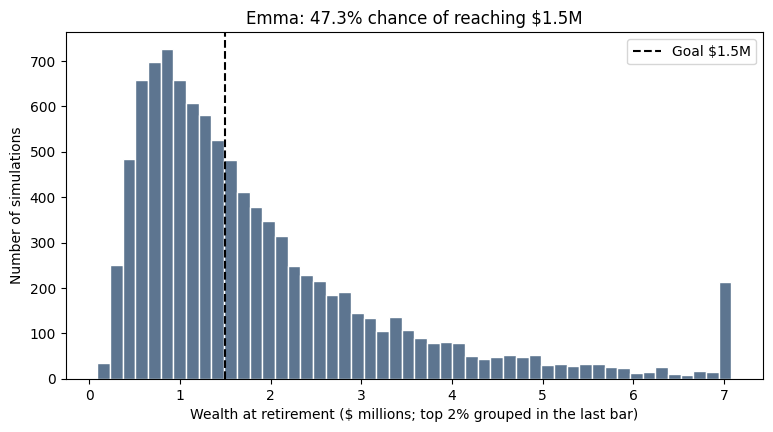

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cap = np.percentile(wealth, 98)
ax.hist(np.minimum(wealth, cap) / 1e6, bins=50, color='#5d7590', edgecolor='white')
ax.axvline(goal / 1e6, color='black', linestyle='--', label=f'Goal ${goal/1e6:.1f}M')
ax.set_xlabel('Wealth at retirement ($ millions; top 2% grouped in the last bar)')
ax.set_ylabel('Number of simulations')
ax.set_title(f"Emma: {(wealth >= goal).mean():.1%} chance of reaching ${goal/1e6:.1f}M")
ax.legend()
plt.show()

## 6. Does it match the website?

These are the numbers the live app shows for Emma's default case (seed 2026). The notebook should match them to the dollar.

In [8]:
app = {'Probability of reaching goal': 0.4727, 'Mean': 1936154.41, 'Median': 1428050.82,
       '5th percentile': 438972.59, '95th percentile': 5081918.12}
mine = {'Probability of reaching goal': (wealth >= goal).mean(), 'Mean': wealth.mean(), 'Median': np.median(wealth),
        '5th percentile': np.percentile(wealth, 5), '95th percentile': np.percentile(wealth, 95)}
check = pd.DataFrame({'Website': app, 'Notebook': mine})
check['Match'] = [abs(check.loc[k, 'Website'] - check.loc[k, 'Notebook']) < (1e-4 if 'Prob' in k else 1) for k in check.index]
fmt = lambda k, x: f"{x:.2%}" if 'Prob' in k else f"${x:,.2f}"
check.assign(
    Website=[fmt(k, x) for k, x in check['Website'].items()],
    Notebook=[fmt(k, x) for k, x in check['Notebook'].items()])

,Website,Notebook,Match
Probability of reaching goal,47.27%,47.27%,True
Mean,"$1,936,154.41","$1,936,154.41",True
Median,"$1,428,050.82","$1,428,050.82",True
5th percentile,"$438,972.59","$438,972.59",True
95th percentile,"$5,081,918.12","$5,081,918.12",True


## 7. Hand checks (answers we know without simulating)

In [9]:
fv_annuity = contribution * ((1 + mean) ** years - 1) / mean
print(f"0% returns every year: ${contribution * years:,.0f}  (12,000 x 35)")
print(f"Expected mean from the formula: ${fv_annuity:,.0f}   Simulated mean: ${wealth.mean():,.0f}  "
      f"({wealth.mean() / fv_annuity - 1:+.1%}, normal random variation)")
w_begin = simulate(timing='begin')
print(f"Beginning-of-year contributions raise the mean by {w_begin.mean() / wealth.mean() - 1:.1%} "
      f"(one extra year of growth = {mean:.1%})")

0% returns every year: $420,000  (12,000 x 35)
Expected mean from the formula: $1,953,152   Simulated mean: $1,936,154  (-0.9%, normal random variation)
Beginning-of-year contributions raise the mean by 7.8% (one extra year of growth = 7.7%)


## 8. What-ifs (same as the demo)

In [10]:
cases = {
    'Emma (default)':                 simulate(),
    'Save $15,000 a year':            simulate(contribution=15_000),
    'Retire at 67':                   simulate(years=37),
    'Historical years instead':       simulate(model='historical'),
}
pd.DataFrame({name: {'Chance of goal': f"{(w >= goal).mean():.1%}", 'Median': f"${np.median(w):,.0f}"} for name, w in cases.items()}).T

,Chance of goal,Median
Emma (default),47.3%,"$1,428,051"
"Save $15,000 a year",59.2%,"$1,785,064"
Retire at 67,54.3%,"$1,635,958"
Historical years instead,48.2%,"$1,445,049"


## 9. For comparison: the NumPy way (like our original notebook)

Using `np.random.normal` gives different random numbers, so the results differ slightly from the app, by the normal sampling noise of 10,000 runs (about 1 percentage point on the probability). This is test 1 in our design document: *matches the notebook within about 1–2%.*

In [11]:
rng = np.random.default_rng(42)
r = rng.normal(mean, sd, size=(n_sims, years))
w_np = np.zeros(n_sims)
for y in range(years):
    w_np = w_np * (1 + r[:, y]) + contribution
pd.DataFrame({'Seeded (matches app)': summary(wealth), 'NumPy normal': summary(w_np)})

,Seeded (matches app),NumPy normal
Probability of reaching goal,47.3%,47.8%
Mean,"$1,936,154","$1,947,203"
Median,"$1,428,051","$1,428,925"
5th percentile,"$438,973","$441,925"
25th percentile,"$861,025","$863,351"
75th percentile,"$2,387,816","$2,392,913"
95th percentile,"$5,081,918","$5,104,788"
